## Components Model



In [5]:
%load_ext autoreload
%autoreload 2
from models.mm_musical_components2 import MelodicComponentsIIMarkovModel
from models.melodic_markov_model import MelodicMarkovModel
from models.mm_mode_region_independent import MarkovModeRegionIndependent
import data.GradualePipeline as gs
import arviz as az
import pymc as pm


In [6]:


data = gs.GradualePipeline.load("data/processed/dataset_pitches.pkl")
model = MelodicComponentsIIMarkovModel()
trace = model.fit(data, use_latest=True, draws=1000, tune=500, description="First try_likelihood")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:

model.build_model()
m = pm.model_to_graphviz(model.model)
m.save("visual/model2.dot")

'visual/model2.dot'

In [13]:
model.build_model()

             pi ~ Dirichlet(<constant>)
     w_interval ~ HalfNormal(0, 1)
register_center ~ Normal(4.5, 4.5)
     w_register ~ HalfNormal(0, 1)
       w_repeat ~ Normal(0, 1)
    w_direction ~ Normal(0, 1)
            x_0 ~ Categorical(pi)
         length ~ Poisson(40)
          x_t+1 ~ CustomDist_x_t+1(x_0, A, length)
              A ~ Deterministic(f(w_direction, w_repeat, w_register, w_interval, register_center))

In [9]:

model2 = MelodicMarkovModel()
trace2 = model2.fit(None, draws=1000, tune=500, chains=4, description="initial_fit_with_likelihood", use_latest=True)

In [19]:

comparison = az.compare({"transition_matrix_model": trace2, "music_components_model": trace}, var_name='transitions')

<Axes: title={'center': 'Model comparison\nhigher is better'}, xlabel='elpd_loo (log)', ylabel='ranked models'>

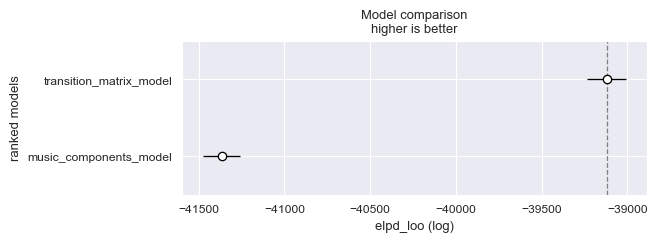

In [20]:
az.plot_compare(comparison)

## Region model Components vs. Independent


In [25]:

model_regio_indep = MarkovModeRegionIndependent()
trace_regio_indep = model_regio_indep.fit(None,use_latest=True, draws=1000, tune=500, description="First try likelihood")

In [26]:
trace_regio_indep

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> observed_data

In [29]:
trace_regio_indep_r = trace_regio_indep.copy()
trace_regio_indep_r.log_likelihood = trace_regio_indep.log_likelihood.rename({"m": "transition"})
trace_regio_indep_r

Inference data with groups:
	> posterior
	> log_likelihood
	> sample_stats
	> observed_data

In [30]:
comparison2 = az.compare({"simple_transition_matrix": trace2, "independent_model": trace_regio_indep}, var_name="transitions")

az.plot_compare(comparison2)

TypeError: Encountered error in ELPD computation of compare.

In [ ]:
comparison2